# Enterprise Causal ML: Out-of-Core Uplift Optimizer
This notebook handles extreme class imbalance via `scale_pos_weight` and prevents RAM crashes via chunking.

### The Core Business Problem: "Correlation vs. Causation"
Standard Machine Learning predicts an outcome (e.g., "Will this user buy this product?").
If a marketing team uses standard ML to distribute a 20% discount code, the algorithm will confidently target users with the highest probability of buying.

This causes a massive business failure: the company just gave a 20% discount to people who were going to buy the product anyway. The marketing campaign burned revenue instead of generating it.

Causal ML fixes this by dividing the customer base into four strict behavioral personas:

Sure Things: Will buy regardless of the discount. (Targeting them wastes money).

Lost Causes: Will never buy, even with the discount. (Targeting them wastes money).

Sleeping Dogs: Will actively get annoyed by the marketing email and unsubscribe/churn. (Targeting them causes negative revenue).

Persuadables: Will only buy if they receive the discount.

# our Project Goal: Build an algorithm that mathematically isolates and targets only the "Persuadables."

In [1]:
!pip install -q xgboost lightgbm scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
import joblib
import warnings
warnings.filterwarnings('ignore')

FILE_PATH = 's3://amzn-s3-hm-clv/uplift/criteo_full.csv'
CHUNK_SIZE = 1000000
features = [f'f{i}' for i in range(12)]

## 1. Exploratory Data Analysis (EDA)
Visualizing the first 500,000 rows to understand the treatment vs control distributions.

Loading initial chunk for EDA...


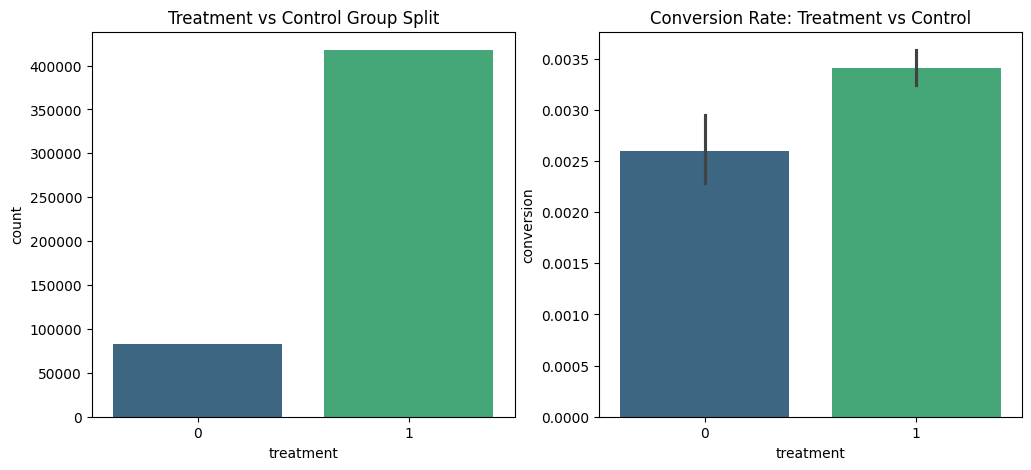

In [3]:
print('Loading initial chunk for EDA...')
df_eda = pd.read_csv(FILE_PATH, nrows=500000)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(x='treatment', data=df_eda, palette='viridis')
plt.title('Treatment vs Control Group Split')

plt.subplot(1, 2, 2)
sns.barplot(x='treatment', y='conversion', data=df_eda, palette='viridis')
plt.title('Conversion Rate: Treatment vs Control')
plt.show()

del df_eda # Clear RAM

## 2. Incremental Training (T-Learner) with Imbalance Weights
We apply `scale_pos_weight: 400` to penalize the models heavily for missing the 0.2% of users who convert.

In [4]:
print("Starting Out-of-Core Incremental Training...")

lgb_params = {'objective': 'binary', 'learning_rate': 0.05, 'max_depth': 6, 'scale_pos_weight': 400, 'verbose': -1}
xgb_params = {'objective': 'binary:logistic', 'learning_rate': 0.05, 'max_depth': 6, 'scale_pos_weight': 400, 'verbosity': 0}

lgb_c, lgb_t = None, None
xgb_c, xgb_t = None, None

chunks = pd.read_csv(FILE_PATH, chunksize=CHUNK_SIZE)
prev_chunk = None

for i, chunk in enumerate(chunks):
    if prev_chunk is not None:
        print(f"Training on Chunk {i}...")
        df_c = prev_chunk[prev_chunk['treatment'] == 0]
        df_t = prev_chunk[prev_chunk['treatment'] == 1]
        
        lgb_train_c = lgb.Dataset(df_c[features], label=df_c['conversion'])
        lgb_train_t = lgb.Dataset(df_t[features], label=df_t['conversion'])
        lgb_c = lgb.train(lgb_params, lgb_train_c, init_model=lgb_c, keep_training_booster=True)
        lgb_t = lgb.train(lgb_params, lgb_train_t, init_model=lgb_t, keep_training_booster=True)

        xgb_train_c = xgb.DMatrix(df_c[features], label=df_c['conversion'])
        xgb_train_t = xgb.DMatrix(df_t[features], label=df_t['conversion'])
        xgb_c = xgb.train(xgb_params, xgb_train_c, xgb_model=xgb_c)
        xgb_t = xgb.train(xgb_params, xgb_train_t, xgb_model=xgb_t)
        
    prev_chunk = chunk

print("\nEvaluating on Final Holdout Chunk...")
test_c = prev_chunk[prev_chunk['treatment'] == 0]
test_t = prev_chunk[prev_chunk['treatment'] == 1]

lgb_auc_c = roc_auc_score(test_c['conversion'], lgb_c.predict(test_c[features]))
lgb_auc_t = roc_auc_score(test_t['conversion'], lgb_t.predict(test_t[features]))
lgb_avg_auc = (lgb_auc_c + lgb_auc_t) / 2

xgb_auc_c = roc_auc_score(test_c['conversion'], xgb_c.predict(xgb.DMatrix(test_c[features])))
xgb_auc_t = roc_auc_score(test_t['conversion'], xgb_t.predict(xgb.DMatrix(test_t[features])))
xgb_avg_auc = (xgb_auc_c + xgb_auc_t) / 2

if lgb_avg_auc > xgb_avg_auc:
    best_t_learner = {'control_model': lgb_c, 'treatment_model': lgb_t, 'features': features, 'type': 'lgb'}
else:
    best_t_learner = {'control_model': xgb_c, 'treatment_model': xgb_t, 'features': features, 'type': 'xgb'}

joblib.dump(best_t_learner, 'uplift_model.pkl')
print("✅ Saved optimal T-Learner to uplift_model.pkl")


Starting Out-of-Core Incremental Training...
Training on Chunk 1...
Training on Chunk 2...
Training on Chunk 3...
Training on Chunk 4...
Training on Chunk 5...
Training on Chunk 6...
Training on Chunk 7...
Training on Chunk 8...
Training on Chunk 9...
Training on Chunk 10...
Training on Chunk 11...
Training on Chunk 12...
Training on Chunk 13...

Evaluating on Final Holdout Chunk...
✅ Saved optimal T-Learner to uplift_model.pkl
